# COTS vs NotCOTS: ResNet18 baseline

Goal: classify cropped images as **crown-of-thorns starfish (COTS)** or **not COTS**.
Method: transfer learning with a ResNet18 pre-trained on ImageNet.


In [ ]:
%pip install -r requirements.txt 

  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached notebook-7.6.5-py3-none-any.whl.metadata (10 kB)
  Using cached jupyter_console-6.6.3-py3-none-any.whl.metadata (5.8 kB)
  Using cached nbconvert-7.17.2-py3-none-any.whl.metadata (8.4 kB)
  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached jupyterlab-4.6.6-py3-none-any.whl.metadata (


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import os, random
import torch, torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## 1. Find where the images are

The dataset's folder layout is not known in advance. This cell prints it: look for the folder that contains **one subfolder per class**.

In [9]:
ROOT = "data"   # on Kaggle. Locally: the folder where you unzipped the dataset
for dirpath, dirnames, filenames in os.walk(ROOT):
    depth = dirpath[len(ROOT):].count(os.sep)
    if depth <= 3:
        print(f"{dirpath}  ->  {len(dirnames)} subfolders, {len(filenames)} files")

data  ->  2 subfolders, 0 files
data\cots_crops  ->  0 subfolders, 11898 files
data\notcots_crops  ->  0 subfolders, 11898 files


In [10]:

DATA_DIR = "data"

## 2. Load and look at the data

In [11]:
IMG_SIZE = 224
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN.flatten().tolist(), STD.flatten().tolist()),
])

full_ds = datasets.ImageFolder(DATA_DIR, transform=tfm)
print("Classes:", full_ds.classes)
print("Number of images:", len(full_ds))
counts = torch.bincount(torch.tensor(full_ds.targets))
for c, n in zip(full_ds.classes, counts):
    print(f"  {c}: {int(n)}")

Classes: ['cots_crops', 'notcots_crops']
Number of images: 23796
  cots_crops: 11898
  notcots_crops: 11898


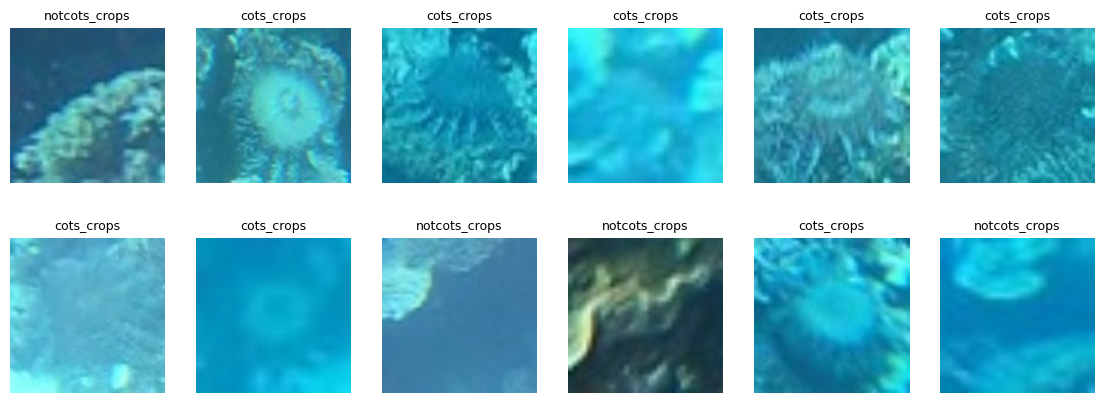

In [12]:
def show(img_t, ax, title=""):
    ax.imshow((img_t * STD + MEAN).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(title, fontsize=9)
    ax.axis("off")

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(axes.flat, random.sample(range(len(full_ds)), 12)):
    x, y = full_ds[i]
    show(x, ax, full_ds.classes[y])
plt.show()

## 3. Split into train / validation / test

Random 70 / 15 / 15 split to start with.
**Known limitation**: these crops come from video frames, so near-identical images can end up in both train and test, which makes the scores too optimistic. We will fix this in a later step.

In [13]:
n = len(full_ds)
n_train, n_val = int(0.70 * n), int(0.15 * n)
n_test = n - n_train - n_val
train_ds, val_ds, test_ds = random_split(
    full_ds, [n_train, n_val, n_test], generator=torch.Generator().manual_seed(SEED)
)

BATCH = 64
NUM_WORKERS = 0  # set to 0 if you get an error on Windows
train_dl = DataLoader(train_ds, BATCH, shuffle=True, num_workers=NUM_WORKERS)
val_dl = DataLoader(val_ds, BATCH, num_workers=NUM_WORKERS)
test_dl = DataLoader(test_ds, BATCH, num_workers=NUM_WORKERS)
print(len(train_ds), len(val_ds), len(test_ds))

16657 3569 3570


## 4. The model: pre-trained ResNet18 with a new last layer

In [14]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(full_ds.classes))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\bousl/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%
